# 03 - Fine-tuning a Projection Head with Triplet Loss

### Approach
* CLIP stays **frozen**. We train only a small residual MLP ("projection head") on top of the
  cached CLIP embeddings.
  * Training takes minutes on a CPU, no GPU required.
  * The trained weights are ~2 MB, small enough for GitHub and a free Streamlit deployment.
* The head is initialised so that, before training, it returns the CLIP embedding unchanged.
  Epoch 0 is therefore exactly the baseline.
* **Triplet loss with batch-hard mining:** each batch holds P marks x K images. For every
  anchor we take its *hardest positive* (the least similar image of the same mark) and its
  *hardest negative* (the most similar image of another mark), and push them apart by a margin:

  `loss = max(0, d(anchor, hardest_pos) - d(anchor, hardest_neg) + margin)`,  with `d = 1 - cosine`.
* The best epoch is chosen on the **validation** split. The test split is untouched until notebook 04.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DATA_DIR = ROOT / "data" / "dummy_logos"
IMAGE_DIR = DATA_DIR / "images"
ASSETS = ROOT / "assets"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for d in (ASSETS, RESULTS, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from model import (ProjectionHead, batch_hard_triplet_loss, pk_batches,
                   apply_head, save_head, get_device)
from metrics import retrieval_eval, summarize

device = get_device()
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

df = pd.read_csv(DATA_DIR / "metadata.csv")
emb = np.load(ROOT / "data" / "embeddings_clip.npy")   # created in notebook 02

train_mask = (df.split == "train").values
val_mask = (df.split == "val").values
X_train = torch.tensor(emb[train_mask], dtype=torch.float32)
y_train = torch.tensor(df.parent_id[train_mask].values)
X_val, y_val = emb[val_mask], df.parent_id[val_mask].values
print("train:", X_train.shape, " val:", X_val.shape)

train: torch.Size([6300, 512])  val: (1350, 512)


## 1. Hyper-parameters

In [2]:
EPOCHS = 60
P, K = 32, 4          # 32 marks x 4 images per batch
MARGIN = 0.2
LR = 1e-3
WEIGHT_DECAY = 1e-4

## 2. Training loop

In [3]:
head = ProjectionHead().to(device)
optimizer = torch.optim.AdamW(head.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def evaluate_val():
    z = apply_head(head, X_val, device)
    return summarize(retrieval_eval(z, y_val))

val0 = evaluate_val()
print("epoch 0 (= CLIP baseline) on val:", {k: round(v, 3) for k, v in val0.items()})

best_score, best_epoch = val0["recall@5"] + val0["mAP"], 0
save_head(head, MODELS / "projection_head.pt", extra={"epoch": 0, "val": val0})
history = [{"epoch": 0, "loss": np.nan, "active_triplets": np.nan, **val0}]

for epoch in range(1, EPOCHS + 1):
    head.train()
    losses, actives = [], []
    for idx in pk_batches(y_train.numpy(), P=P, K=K, rng=rng):
        idx = torch.as_tensor(idx)
        xb, yb = X_train[idx].to(device), y_train[idx].to(device)
        loss, active = batch_hard_triplet_loss(head(xb), yb, margin=MARGIN)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        actives.append(active.item())
    scheduler.step()

    val = evaluate_val()
    history.append({"epoch": epoch, "loss": np.mean(losses),
                    "active_triplets": np.mean(actives), **val})
    score = val["recall@5"] + val["mAP"]
    if score > best_score:
        best_score, best_epoch = score, epoch
        save_head(head, MODELS / "projection_head.pt", extra={"epoch": epoch, "val": val})
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d}  loss {np.mean(losses):.4f}  "
              f"R@1 {val['recall@1']:.3f}  R@5 {val['recall@5']:.3f}  mAP {val['mAP']:.3f}")

print(f"\nBest epoch: {best_epoch}  -> saved to models/projection_head.pt")

epoch 0 (= CLIP baseline) on val: {'recall@1': 0.905, 'recall@5': 0.95, 'recall@10': 0.959, 'mAP': 0.681}
epoch   1  loss 0.1776  R@1 0.931  R@5 0.964  mAP 0.761
epoch   5  loss 0.0632  R@1 0.963  R@5 0.990  mAP 0.895
epoch  10  loss 0.0350  R@1 0.975  R@5 0.993  mAP 0.920
epoch  15  loss 0.0249  R@1 0.978  R@5 0.996  mAP 0.931
epoch  20  loss 0.0204  R@1 0.980  R@5 0.995  mAP 0.938
epoch  25  loss 0.0184  R@1 0.979  R@5 0.996  mAP 0.943
epoch  30  loss 0.0153  R@1 0.981  R@5 0.997  mAP 0.944
epoch  35  loss 0.0166  R@1 0.981  R@5 0.999  mAP 0.945
epoch  40  loss 0.0109  R@1 0.985  R@5 0.997  mAP 0.950
epoch  45  loss 0.0139  R@1 0.984  R@5 0.999  mAP 0.951
epoch  50  loss 0.0096  R@1 0.986  R@5 0.999  mAP 0.952
epoch  55  loss 0.0111  R@1 0.984  R@5 0.999  mAP 0.953
epoch  60  loss 0.0102  R@1 0.984  R@5 0.999  mAP 0.953

Best epoch: 59  -> saved to models/projection_head.pt


## 3. Training curves

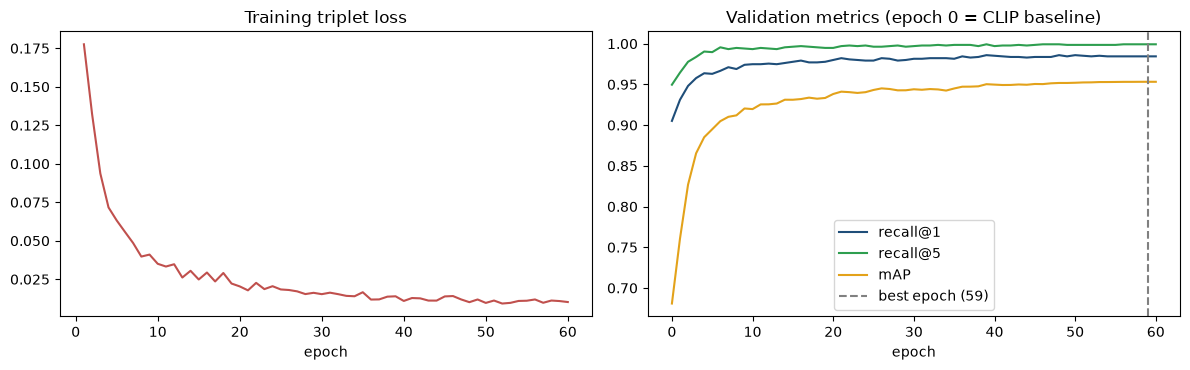

In [4]:
hist = pd.DataFrame(history)
hist.to_csv(RESULTS / "training_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(hist.epoch, hist.loss, color="#c0504d")
axes[0].set_title("Training triplet loss")
axes[0].set_xlabel("epoch")
for col, color in [("recall@1", "#1f4e79"), ("recall@5", "#2e9e4f"), ("mAP", "#e3a21a")]:
    axes[1].plot(hist.epoch, hist[col], label=col, color=color)
axes[1].axvline(best_epoch, ls="--", color="grey", label=f"best epoch ({best_epoch})")
axes[1].set_title("Validation metrics (epoch 0 = CLIP baseline)")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(ASSETS / "training_curves.png", dpi=110, bbox_inches="tight")
plt.show()

In [5]:
comparison = pd.DataFrame({"CLIP baseline (val)": val0,
                           "Fine-tuned (val, best epoch)": hist.loc[best_epoch, list(val0)].to_dict()})
comparison.style.format("{:.3f}")

,CLIP baseline (val),"Fine-tuned (val, best epoch)"
recall@1,0.905,0.984
recall@5,0.950,0.999
recall@10,0.959,0.999
mAP,0.681,0.953


## Notes
* If validation metrics stop improving early, the head may be over-fitting: try fewer
  epochs, a larger margin (0.3) or a smaller hidden layer.
* The real verdict comes from the **test** split in notebook 04.